# Datenexploration: The Movies Dataset

Dieses Notebook untersucht die CSV-Dateien unter `datasets/kaggle`. Der Datensatz kombiniert TMDB-Filme und Metadaten mit MovieLens-Bewertungen und Zuordnungstabellen. Die Exploration betrachtet Datenqualitaet, Genres, Schlagwoerter, Besetzung, Bewertungen und die Verknuepfbarkeit der Tabellen als Grundlage fuer ein Empfehlungssystem.

**Hinweis:** `ratings.csv` ist mehrere hundert Megabyte gross und wird deshalb blockweise verarbeitet. Die verschachtelten Listen in `genres`, `keywords`, `cast` und `crew` sind als Text gespeichert und werden mit `ast.literal_eval` sicher interpretiert. Benoetigt werden `pandas` und `matplotlib`; das Notebook erwartet, dass es aus dem Projektverzeichnis gestartet wird.

In [6]:
import ast
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA_DIR = Path.cwd() / 'datasets' / 'kaggle'
if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'Dataset-Ordner nicht gefunden: {DATA_DIR.resolve()}')

CSV_FILES = sorted(DATA_DIR.glob('*.csv'))
if not CSV_FILES:
    raise FileNotFoundError(f'Keine CSV-Dateien gefunden: {DATA_DIR.resolve()}')

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_colwidth', 120)

inventory = pd.DataFrame({
    'Datei': [path.name for path in CSV_FILES],
    'Groesse (MB)': [round(path.stat().st_size / 1024**2, 2) for path in CSV_FILES],
}).sort_values('Datei')
display(inventory)

MOVIES_PATH = DATA_DIR / 'movies_metadata.csv'
CREDITS_PATH = DATA_DIR / 'credits.csv'
KEYWORDS_PATH = DATA_DIR / 'keywords.csv'
LINKS_PATH = DATA_DIR / 'links.csv'
LINKS_SMALL_PATH = DATA_DIR / 'links_small.csv'
RATINGS_PATH = DATA_DIR / 'ratings.csv'
RATINGS_SMALL_PATH = DATA_DIR / 'ratings_small.csv'

,Datei,Groesse (MB)
0,credits.csv,181.12
1,keywords.csv,5.94
2,links.csv,0.94
3,links_small.csv,0.17
4,movies_metadata.csv,32.85
5,ratings.csv,676.68
6,ratings_small.csv,2.33


## Filmkatalog: Struktur, Qualitaet und Genres

Die Metadaten enthalten teils fehlende oder nicht numerische Werte sowie als Zeichenketten gespeicherte Listen. Die Umwandlungen unten werden deshalb explizit und mit Fehlerbehandlung vorgenommen.

Form: 45,466 Zeilen x 24 Spalten


,adult,belongs_to_collection,budget,genres,homepage,id,imdb_id,original_language,original_title,overview,popularity,poster_path,production_companies,production_countries,release_date,revenue,runtime,spoken_languages,status,tagline,title,video,vote_average,vote_count
0,False,"{'id': 10194, 'name': 'Toy Story Collection', 'poster_path': '/7G9915LfUQ2lVfwMEEhDsn3kT4B.jpg', 'backdrop_path': '/...",30000000,"[{'id': 16, 'name': 'Animation'}, {'id': 35, 'name': 'Comedy'}, {'id': 10751, 'name': 'Family'}]",http://toystory.disney.com/toy-story,862,tt0114709,en,Toy Story,"Led by Woody, Andy's toys live happily in his room until Andy's birthday brings Buzz Lightyear onto the scene. Afrai...",21.946943,/rhIRbceoE9lR4veEXuwCC2wARtG.jpg,"[{'name': 'Pixar Animation Studios', 'id': 3}]","[{'iso_3166_1': 'US', 'name': 'United States of America'}]",1995-10-30,373554033.0,81.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,NaN,Toy Story,False,7.7,5415.0
1,False,NaN,65000000,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, 'name': 'Fantasy'}, {'id': 10751, 'name': 'Family'}]",NaN,8844,tt0113497,en,Jumanji,"When siblings Judy and Peter discover an enchanted board game that opens the door to a magical world, they unwitting...",17.015539,/vzmL6fP7aPKNKPRTFnZmiUfciyV.jpg,"[{'name': 'TriStar Pictures', 'id': 559}, {'name': 'Teitler Film', 'id': 2550}, {'name': 'Interscope Communications'...","[{'iso_3166_1': 'US', 'name': 'United States of America'}]",1995-12-15,262797249.0,104.0,"[{'iso_639_1': 'en', 'name': 'English'}, {'iso_639_1': 'fr', 'name': 'Français'}]",Released,Roll the dice and unleash the excitement!,Jumanji,False,6.9,2413.0
2,False,"{'id': 119050, 'name': 'Grumpy Old Men Collection', 'poster_path': '/nLvUdqgPgm3F85NMCii9gVFUcet.jpg', 'backdrop_pat...",0,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, 'name': 'Comedy'}]",NaN,15602,tt0113228,en,Grumpier Old Men,"A family wedding reignites the ancient feud between next-door neighbors and fishing buddies John and Max. Meanwhile,...",11.7129,/6ksm1sjKMFLbO7UY2i6G1ju9SML.jpg,"[{'name': 'Warner Bros.', 'id': 6194}, {'name': 'Lancaster Gate', 'id': 19464}]","[{'iso_3166_1': 'US', 'name': 'United States of America'}]",1995-12-22,0.0,101.0,"[{'iso_639_1': 'en', 'name': 'English'}]",Released,Still Yelling. Still Fighting. Still Ready for Love.,Grumpier Old Men,False,6.5,92.0


,Fehlende Werte,Fehlend (%),Eindeutige Werte
belongs_to_collection,40972,90.1,1698
homepage,37684,82.9,7673
tagline,25054,55.1,20283
overview,954,2.1,44307
poster_path,386,0.8,45024
runtime,263,0.6,353
release_date,87,0.2,17336
status,87,0.2,6
adult,0,0.0,5
vote_average,6,0.0,92


Doppelte Film-IDs: 30


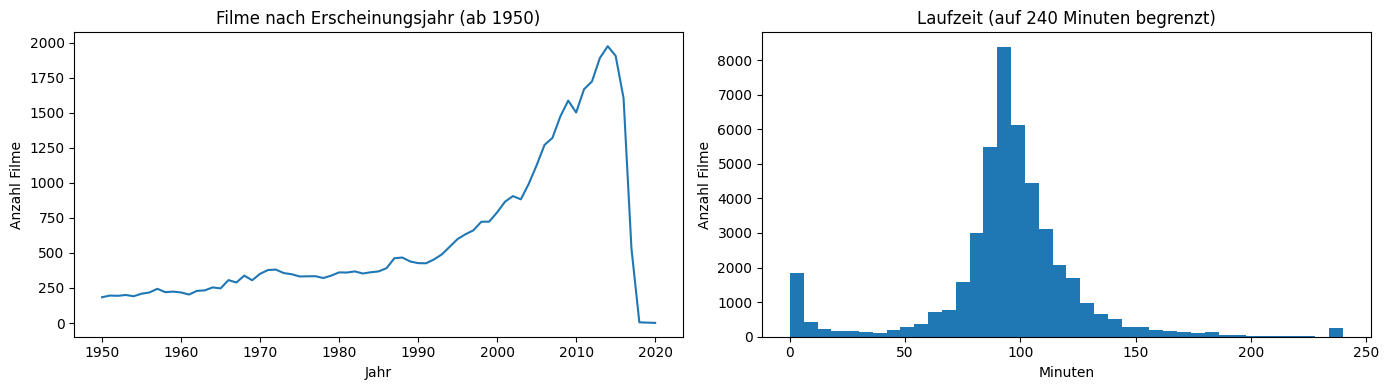

,Genre,Filme
0,Drama,20265
1,Comedy,13182
2,Thriller,7624
3,Romance,6735
4,Action,6596
5,Horror,4673
6,Crime,4307
7,Documentary,3932
8,Adventure,3496
9,Science Fiction,3049


,Filme
original_language,
en,32269
fr,2438
it,1529
ja,1350
de,1080
es,994
ru,826
hi,508
ko,444


,budget_num,revenue_num,profit
count,5381.0,5.381000e+03,5.381000e+03
mean,31094796.0,9.031812e+07,5.922333e+07
std,40162625.5,1.661423e+08,1.395368e+08
min,1.0,1.000000e+00,-1.657101e+08
25%,5037000.0,7.011317e+06,-1.468000e+06
50%,17000000.0,2.991874e+07,1.108426e+07
75%,40000000.0,9.996575e+07,6.212776e+07
max,380000000.0,2.787965e+09,2.550965e+09


In [7]:
movies = pd.read_csv(MOVIES_PATH, low_memory=False)
print(f'Form: {movies.shape[0]:,} Zeilen x {movies.shape[1]} Spalten')
display(movies.head(3))

quality = pd.DataFrame({
    'Fehlende Werte': movies.isna().sum(),
    'Fehlend (%)': (movies.isna().mean() * 100).round(1),
    'Eindeutige Werte': movies.nunique(dropna=True),
}).sort_values('Fehlend (%)', ascending=False)
display(quality)
print('Doppelte Film-IDs:', int(movies['id'].duplicated().sum()))

movies['release_year'] = pd.to_datetime(movies['release_date'], errors='coerce').dt.year
numeric_columns = ['budget', 'revenue', 'runtime', 'popularity', 'vote_average', 'vote_count']
for column in numeric_columns:
    movies[column + '_num'] = pd.to_numeric(movies[column], errors='coerce')

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
movies['release_year'].dropna().astype(int).value_counts().sort_index().loc[lambda s: s.index >= 1950].plot(ax=axes[0])
axes[0].set(title='Filme nach Erscheinungsjahr (ab 1950)', xlabel='Jahr', ylabel='Anzahl Filme')
movies['runtime_num'].dropna().clip(upper=240).plot.hist(bins=40, ax=axes[1])
axes[1].set(title='Laufzeit (auf 240 Minuten begrenzt)', xlabel='Minuten', ylabel='Anzahl Filme')
plt.tight_layout()
plt.show()

PARSE_FAILURES = 0

def parse_list(value):
    global PARSE_FAILURES
    if not isinstance(value, str) or not value.strip():
        return []
    try:
        parsed = ast.literal_eval(value)
    except (ValueError, SyntaxError):
        PARSE_FAILURES += 1
        return []
    if not isinstance(parsed, list):
        PARSE_FAILURES += 1
        return []
    return parsed

genre_counts = Counter(
    item['name']
    for value in movies['genres'].dropna()
    for item in parse_list(value)
    if isinstance(item, dict) and item.get('name')
)
display(pd.DataFrame(genre_counts.most_common(15), columns=['Genre', 'Filme']))
display(movies['original_language'].value_counts(dropna=False).head(10).rename('Filme').to_frame())

financials = movies[['budget_num', 'revenue_num']].query('budget_num > 0 and revenue_num > 0').copy()
financials['profit'] = financials['revenue_num'] - financials['budget_num']
display(financials[['budget_num', 'revenue_num', 'profit']].describe().round(1))

## Schlagwoerter und Filmcredits

`keywords.csv` und `credits.csv` enthalten Python-aehnliche Listen als Text. Die Analyse liest diese Dateien in kleineren Bloecken und extrahiert haeufige Schlagwoerter, Darsteller und Crew-Funktionen, ohne die grossen CSVs komplett im Speicher zu halten.

In [8]:
def count_nested_values(path, column, key, chunk_size=5000):
    counts = Counter()
    record_lengths = []
    row_count = 0
    for chunk in pd.read_csv(path, usecols=[column], chunksize=chunk_size):
        row_count += len(chunk)
        for value in chunk[column]:
            records = parse_list(value)
            record_lengths.append(len(records))
            counts.update(
                record[key]
                for record in records
                if isinstance(record, dict) and record.get(key)
            )
    return counts, row_count, record_lengths

keyword_counts, keyword_rows, keyword_lengths = count_nested_values(KEYWORDS_PATH, 'keywords', 'name')
print(f'keywords.csv: {keyword_rows:,} Filme; durchschnittlich {sum(keyword_lengths) / max(keyword_rows, 1):.1f} Schlagwoerter je Film')
display(pd.DataFrame(keyword_counts.most_common(20), columns=['Schlagwort', 'Vorkommen']))

cast_counts, credit_rows, cast_lengths = count_nested_values(CREDITS_PATH, 'cast', 'name')
crew_jobs, _, _ = count_nested_values(CREDITS_PATH, 'crew', 'job')
print(f'credits.csv: {credit_rows:,} Filme; durchschnittlich {sum(cast_lengths) / max(credit_rows, 1):.1f} aufgefuehrte Darsteller je Film')
display(pd.DataFrame(cast_counts.most_common(15), columns=['Darsteller/in', 'Credits']))
display(pd.DataFrame(crew_jobs.most_common(15), columns=['Crew-Funktion', 'Credits']))
print(f'Nicht lesbare oder unerwartet formatierte Listenwerte: {PARSE_FAILURES:,}')

keywords.csv: 46,419 Filme; durchschnittlich 3.4 Schlagwoerter je Film


,Schlagwort,Vorkommen
0,woman director,3115
1,independent film,1930
2,murder,1308
3,based on novel,835
4,musical,734
5,sex,685
6,violence,651
7,nudity,636
8,biography,629
9,revenge,626


credits.csv: 45,476 Filme; durchschnittlich 12.4 aufgefuehrte Darsteller je Film


,Darsteller/in,Credits
0,Bess Flowers,241
1,Christopher Lee,148
2,John Wayne,125
3,Samuel L. Jackson,123
4,Gérard Depardieu,110
5,Michael Caine,110
6,Donald Sutherland,109
7,John Carradine,109
8,Jackie Chan,108
9,Frank Welker,107


,Crew-Funktion,Credits
0,Director,49048
1,Producer,43555
2,Writer,30431
3,Screenplay,25163
4,Editor,23800
5,Director of Photography,20659
6,Executive Producer,18866
7,Original Music Composer,15790
8,Casting,12635
9,Art Direction,11689


Nicht lesbare oder unerwartet formatierte Listenwerte: 0


## MovieLens-Bewertungen und Empfehlungssignale

Die Bewertungen liegen sowohl als grosse Datei als auch als kleinere Stichprobe vor. Die Blockaggregation berechnet Verteilungen, Aktivitaet pro Nutzer/in und Filmstatistiken; so bleiben Speicherbedarf und Laufzeit auch fuer `ratings.csv` kontrollierbar. Bei den Top-Filmen werden Mittelwerte erst ab mindestens 20 Bewertungen verglichen.

,Bewertungen,Nutzer/innen,Filme mit Bewertung,Mittelwert,Zeitraum
Datensatz,,,,,
ratings.csv,26024289,270896,45115,3.53,1995-01-09 bis 2017-08-04
ratings_small.csv,100004,671,9066,3.54,1995-01-09 bis 2016-10-16


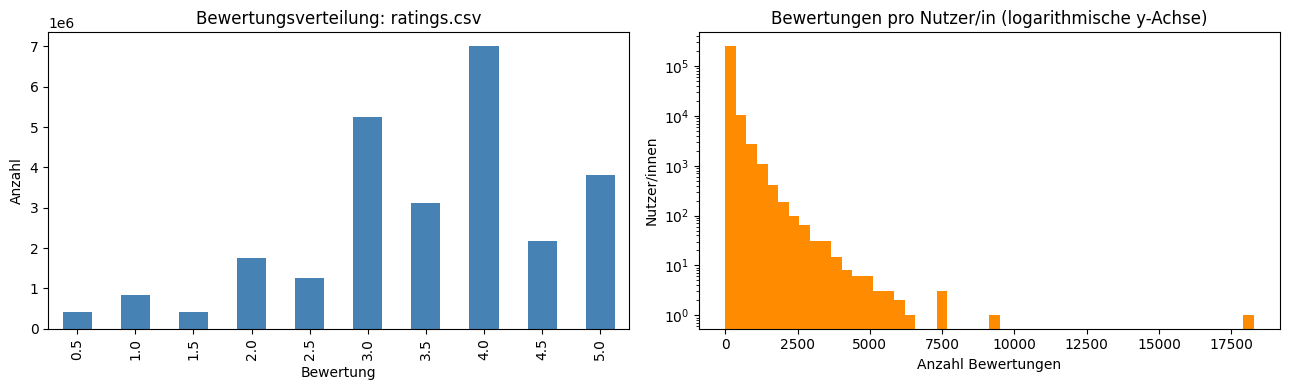

In [9]:
def aggregate_ratings(path, chunk_size=500_000):
    rating_counts = pd.Series(dtype='float64')
    movie_stats = pd.DataFrame(columns=['rating_sum', 'rating_count'], dtype='float64')
    user_counts = pd.Series(dtype='float64')
    min_timestamp, max_timestamp, row_count = None, None, 0
    dtypes = {'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int64'}

    for chunk in pd.read_csv(path, chunksize=chunk_size, dtype=dtypes):
        row_count += len(chunk)
        rating_counts = rating_counts.add(chunk['rating'].value_counts(), fill_value=0)
        movie_part = chunk.groupby('movieId')['rating'].agg(['sum', 'count']).rename(
            columns={'sum': 'rating_sum', 'count': 'rating_count'}
        )
        movie_stats = movie_stats.add(movie_part, fill_value=0)
        user_counts = user_counts.add(chunk.groupby('userId').size(), fill_value=0)
        chunk_min, chunk_max = int(chunk['timestamp'].min()), int(chunk['timestamp'].max())
        min_timestamp = chunk_min if min_timestamp is None else min(min_timestamp, chunk_min)
        max_timestamp = chunk_max if max_timestamp is None else max(max_timestamp, chunk_max)

    movie_stats['mean_rating'] = movie_stats['rating_sum'] / movie_stats['rating_count']
    return {
        'row_count': row_count,
        'rating_counts': rating_counts.sort_index(),
        'movie_stats': movie_stats,
        'user_counts': user_counts,
        'min_timestamp': min_timestamp,
        'max_timestamp': max_timestamp,
    }

ratings = aggregate_ratings(RATINGS_PATH)
ratings_small = aggregate_ratings(RATINGS_SMALL_PATH)

def rating_summary(label, result):
    return {
        'Datensatz': label,
        'Bewertungen': result['row_count'],
        'Nutzer/innen': len(result['user_counts']),
        'Filme mit Bewertung': len(result['movie_stats']),
        'Mittelwert': round(result['movie_stats']['rating_sum'].sum() / result['row_count'], 2),
        'Zeitraum': f"{pd.to_datetime(result['min_timestamp'], unit='s').date()} bis {pd.to_datetime(result['max_timestamp'], unit='s').date()}",
    }

display(pd.DataFrame([
    rating_summary('ratings.csv', ratings),
    rating_summary('ratings_small.csv', ratings_small),
]).set_index('Datensatz'))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ratings['rating_counts'].plot.bar(ax=axes[0], color='steelblue')
axes[0].set(title='Bewertungsverteilung: ratings.csv', xlabel='Bewertung', ylabel='Anzahl')
ratings['user_counts'].plot.hist(bins=50, log=True, ax=axes[1], color='darkorange')
axes[1].set(title='Bewertungen pro Nutzer/in (logarithmische y-Achse)', xlabel='Anzahl Bewertungen', ylabel='Nutzer/innen')
plt.tight_layout()
plt.show()

## Tabellenverknuepfung und Kandidaten fuer Empfehlungen

`movieId` aus MovieLens wird ueber `links.csv` auf `tmdbId` und anschliessend auf die Film-ID in `movies_metadata.csv` abgebildet. Die Abdeckung dieser Kette ist wichtig, wenn Bewertungen mit Genres, Titeln oder weiteren TMDB-Merkmalen kombiniert werden sollen.

In [10]:
links = pd.read_csv(LINKS_PATH, dtype={'movieId': 'string', 'tmdbId': 'string'})
links_small = pd.read_csv(LINKS_SMALL_PATH, dtype={'movieId': 'string', 'tmdbId': 'string'})
metadata_ids = set(movies['id'].dropna().astype('string').str.strip())
linked_tmdb_ids = set(links['tmdbId'].dropna().str.strip())
rated_movie_ids = set(ratings['movie_stats'].index.astype(str))
linked_movie_ids = set(links['movieId'].dropna().str.strip())
mapped_rated_ids = rated_movie_ids & linked_movie_ids
mapped_rating_count = ratings['movie_stats'].loc[
    ratings['movie_stats'].index.astype(str).isin(mapped_rated_ids), 'rating_count'
].sum()

link_summary = pd.DataFrame([
    {'Tabelle': 'links.csv', 'Zeilen': len(links), 'MovieLens-IDs': links['movieId'].nunique(), 'TMDB-IDs': links['tmdbId'].notna().sum()},
    {'Tabelle': 'links_small.csv', 'Zeilen': len(links_small), 'MovieLens-IDs': links_small['movieId'].nunique(), 'TMDB-IDs': links_small['tmdbId'].notna().sum()},
])
display(link_summary.set_index('Tabelle'))
print(f'TMDB-IDs aus links.csv, die in movies_metadata.csv vorkommen: {len(linked_tmdb_ids & metadata_ids):,} / {len(linked_tmdb_ids):,}')
print(f'Bewertete MovieLens-Filme mit Eintrag in links.csv: {len(mapped_rated_ids):,} / {len(rated_movie_ids):,}')
print(f'Bewertungen auf Filme mit MovieLens-Link: {mapped_rating_count:,.0f} / {ratings["row_count"]:,} ({mapped_rating_count / ratings["row_count"]:.1%})')

movie_stats = ratings['movie_stats'].copy()
movie_stats.index = movie_stats.index.astype(str)
movie_to_tmdb = links.dropna(subset=['tmdbId']).copy()
movie_to_tmdb['movieId'] = movie_to_tmdb['movieId'].str.strip()
movie_to_tmdb['tmdbId'] = movie_to_tmdb['tmdbId'].str.strip()
movie_to_tmdb = movie_to_tmdb.drop_duplicates('movieId').set_index('movieId')['tmdbId']
titles = movies[['id', 'title']].dropna(subset=['id']).copy()
titles['id'] = titles['id'].astype('string').str.strip()
titles = titles.drop_duplicates('id').set_index('id')['title']
movie_stats['tmdbId'] = movie_stats.index.map(movie_to_tmdb)
movie_stats['title'] = movie_stats['tmdbId'].map(titles)

print('Am haeufigsten bewertete Filme:')
display(movie_stats.sort_values('rating_count', ascending=False)[['title', 'rating_count', 'mean_rating']].head(10))
print('Am besten bewertete Filme (mindestens 20 Bewertungen):')
display(movie_stats.query('rating_count >= 20').sort_values('mean_rating', ascending=False)[['title', 'rating_count', 'mean_rating']].head(10).round(2))

,Zeilen,MovieLens-IDs,TMDB-IDs
Tabelle,,,
links.csv,45843,45843,45624
links_small.csv,9125,9125,9112


TMDB-IDs aus links.csv, die in movies_metadata.csv vorkommen: 45,433 / 45,594
Bewertete MovieLens-Filme mit Eintrag in links.csv: 45,115 / 45,115
Bewertungen auf Filme mit MovieLens-Link: 26,024,289 / 26,024,289 (100.0%)
Am haeufigsten bewertete Filme:


,title,rating_count,mean_rating
movieId,,,
356,Forrest Gump,91921.0,4.052926
318,The Shawshank Redemption,91082.0,4.429015
296,Pulp Fiction,87901.0,4.169975
593,The Silence of the Lambs,84078.0,4.152246
2571,The Matrix,77960.0,4.154098
260,Star Wars,77045.0,4.132299
480,Jurassic Park,74355.0,3.660238
527,Schindler's List,67662.0,4.266531
110,Braveheart,66512.0,4.016057


Am besten bewertete Filme (mindestens 20 Bewertungen):


,title,rating_count,mean_rating
movieId,,,
159817,Planet Earth,754.0,4.48
318,The Shawshank Redemption,91082.0,4.43
170705,Band of Brothers,284.0,4.39
171011,Planet Earth II,95.0,4.35
858,The Godfather,57070.0,4.34
50,The Usual Suspects,59271.0,4.30
100044,NaN,197.0,4.27
527,Schindler's List,67662.0,4.27
143511,Human,34.0,4.26


## Einordnung

Die Tabellen liefern komplementaere Signale: MovieLens-Bewertungen bilden Nutzer-Film-Interaktionen ab, waehrend TMDB-Genres, Schlagwoerter und Credits inhaltsbasierte Merkmale liefern. Vor dem Training sollten fehlerhafte oder doppelte Film-IDs bereinigt, die Link-Abdeckung beruecksichtigt und die unterschiedliche Groesse von `ratings.csv` und `ratings_small.csv` beachtet werden. Die Top-Bewertungslisten sind deskriptiv; eine Mindestanzahl an Bewertungen verhindert, dass Filme mit nur wenigen Stimmen unkritisch an die Spitze gelangen.